Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to C:\Users\jhdka/.cache\torch\hub\checkpoints\mobilenet_v2-7ebf99e0.pth


100.0%


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\jhdka/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100.0%



Fine-tuning MobileNetV2...

--- Detailed Classification Report for MobileNetV2 ---
              precision    recall  f1-score   support

       daisy     0.7423    0.7500    0.7461        96
   dandelion     0.8485    0.8235    0.8358       136
        rose     0.7009    0.8454    0.7664        97
   sunflower     0.8333    0.8019    0.8173       106
       tulip     0.8519    0.7603    0.8035       121

    accuracy                         0.7968       556
   macro avg     0.7954    0.7962    0.7938       556
weighted avg     0.8022    0.7968    0.7976       556



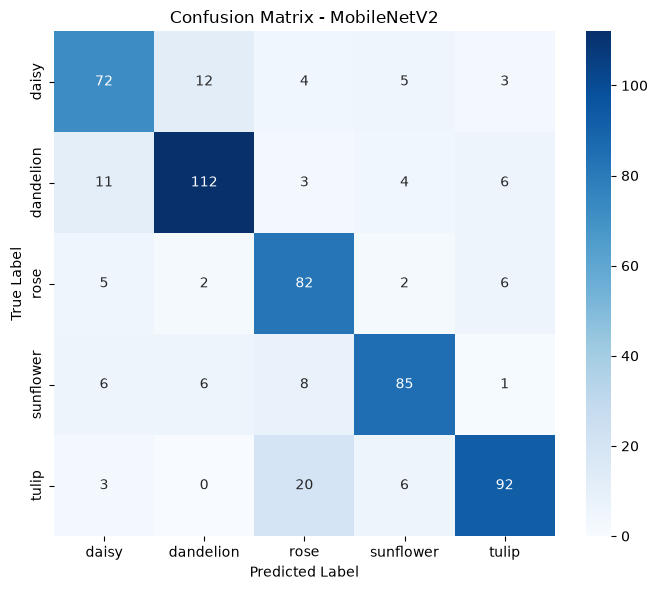


Fine-tuning EfficientNet-B0...

--- Detailed Classification Report for EfficientNet-B0 ---
              precision    recall  f1-score   support

       daisy     0.8409    0.7708    0.8043        96
   dandelion     0.9194    0.8382    0.8769       136
        rose     0.7105    0.8351    0.7678        97
   sunflower     0.8130    0.9434    0.8734       106
       tulip     0.8411    0.7438    0.7895       121

    accuracy                         0.8255       556
   macro avg     0.8250    0.8263    0.8224       556
weighted avg     0.8321    0.8255    0.8256       556



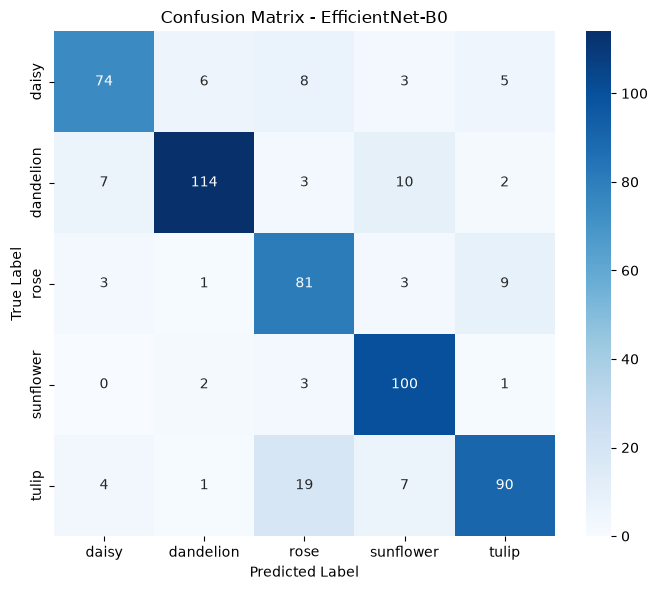

In [1]:
import os
import sys
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

from models.sota_models import get_mobilenet_v2, get_efficientnet_b0
from utils.metrics import compute_and_plot_metrics

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

TRAIN_DIR = os.path.join(PROJECT_ROOT, "data", "train")
TEST_DIR = os.path.join(PROJECT_ROOT, "data", "test")

train_dataset = datasets.ImageFolder(root=TRAIN_DIR, transform=transform)
test_dataset = datasets.ImageFolder(root=TEST_DIR, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
class_names = train_dataset.classes

sota_models = {
    'MobileNetV2': get_mobilenet_v2(num_classes=5),
    'EfficientNet-B0': get_efficientnet_b0(num_classes=5)
}

criterion = nn.CrossEntropyLoss()

for name, model in sota_models.items():
    print(f"\nFine-tuning {name}...")
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.0005) # Lower LR for fine-tuning
    
    # Train for 20 epochs
    for epoch in range(20):
        model.train()
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs), labels)
            loss.backward()
            optimizer.step()
            
    # Test Evaluation
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    # Compute Metrics
    compute_and_plot_metrics(all_labels, all_preds, class_names, model_name=name)